# Final HepatoXAI-RF Revised Analysis

This notebook reproduces the final analyses and figures reported in the revised manuscript.

## 1. Mount Google Drive and install the Excel dependency

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install openpyxl

Mounted at /content/drive


## 2. Imports and original Drive paths

In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import skew, boxcox
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

BASE_PATH = '/content/drive/MyDrive'
DATA_PATH = f'{BASE_PATH}/HBV_Dataset.xlsx'
OUT_DIR = Path('/content/drive/MyDrive/HBV_RF_Final_Outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = 'Status'

print('Dataset path:', DATA_PATH)
print('File exists:', os.path.exists(DATA_PATH))
print('Output directory:', OUT_DIR)

Dataset path: /content/drive/MyDrive/HBV_Dataset.xlsx
File exists: True
Output directory: /content/drive/MyDrive/HBV_RF_Final_Outputs


## 3. Original column definitions and parsing logic

In [3]:
NUM_COLS = ['Age', 'HBVDNA', 'ALTLevel', 'ASTLevel', 'Bilirubin']
CAT_COLS = ['Gender', 'Jaundice', 'DarkUrine', 'AbdominalPain', 'VomitingFrequency', 'LossofAppetite']

ENCODING_MAPS = {
    'Gender': {'F': 0, 'M': 1},
    'Jaundice': {'no': 0, 'yes': 1},
    'DarkUrine': {'no': 0, 'yes': 1},
    'AbdominalPain': {'none': 0, 'mild': 1, 'moderate': 2, 'severe': 3},
    'VomitingFrequency': {'none': 0, 'rare': 1, 'moderate': 2, 'frequent': 3},
    'LossofAppetite': {'no': 0, 'yes': 1},
    'Status': {'Negative': 0, 'Positive': 1}
}

def parse_hbvdna(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, str):
        s = x.strip()
        if s.lower() == 'not detected':
            return 0.0
        try:
            return float(s)
        except Exception:
            return np.nan
    return float(x)

## 4. Load and inspect the dataset

In [4]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'Dataset not found at {DATA_PATH}. Place HBV_Dataset.xlsx directly in MyDrive.'
    )

df = pd.read_excel(DATA_PATH)
df.columns = df.columns.str.strip()
df['HBVDNA'] = df['HBVDNA'].apply(parse_hbvdna)

print('Shape:', df.shape)
display(df.head())
print('\nMissing values:')
display(df.isna().sum().to_frame('Missing'))

Shape: (216, 13)


,Age,Gender,Jaundice,DarkUrine,AbdominalPain,VomitingFrequency,LossofAppetite,HBVDNA,ALTLevel,ASTLevel,Bilirubin,Albumin,Status
0,66,F,yes,yes,mild,moderate,yes,2.990000e+11,77.4,104.0,5.90,NaN,Positive
1,69,M,no,no,mild,rare,yes,2.740095e+06,116.0,90.0,0.79,3.80,Positive
2,20,F,no,no,mild,rare,yes,5.483606e+07,68.0,40.0,0.72,3.80,Positive
3,29,M,no,no,mild,rare,yes,3.350000e+07,49.2,45.4,0.45,NaN,Positive
4,30,M,no,no,none,none,no,5.186982e+07,34.4,28.5,0.34,3.68,Positive



Missing values:


,Missing
Age,0
Gender,0
Jaundice,20
DarkUrine,20
AbdominalPain,17
VomitingFrequency,17
LossofAppetite,17
HBVDNA,2
ALTLevel,17
ASTLevel,18


## 5. Reproduce the original EDA preprocessing

This section preserves the original median and mode imputation, categorical encoding, skewness rule, Box-Cox transformation, and standardization used to construct the original figures.

In [5]:
eda_df = df.copy()

if 'Albumin' in eda_df.columns:
    eda_df = eda_df.drop(columns=['Albumin'])

EDA_NUM_COLS = [col for col in NUM_COLS if col in eda_df.columns]
EDA_CAT_COLS = [col for col in CAT_COLS if col in eda_df.columns]

for col in EDA_NUM_COLS:
    eda_df[col] = eda_df[col].fillna(eda_df[col].median())

for col in EDA_CAT_COLS:
    eda_df[col] = eda_df[col].fillna(eda_df[col].mode()[0])

for col, mapping in ENCODING_MAPS.items():
    if col in eda_df.columns:
        eda_df[col] = eda_df[col].map(mapping)

eda_boxcox_df = eda_df.copy()
boxcox_info = {}

for col in EDA_NUM_COLS:
    values = eda_boxcox_df[col].astype(float)
    feature_skewness = skew(values.dropna())

    if abs(feature_skewness) > 1:
        minimum = values.min()
        shift = 1.0 if minimum > 0 else abs(minimum) + 1.0
        transformed, fitted_lambda = boxcox(values.values + shift)
        eda_boxcox_df[col] = transformed
        boxcox_info[col] = {
            'original_skewness': feature_skewness,
            'lambda': fitted_lambda,
            'shift': shift
        }
    else:
        boxcox_info[col] = {
            'original_skewness': feature_skewness,
            'lambda': None,
            'shift': None
        }

eda_scaled_df = eda_boxcox_df.copy()
scaler_eda = StandardScaler()
eda_scaled_df[EDA_NUM_COLS] = scaler_eda.fit_transform(
    eda_scaled_df[EDA_NUM_COLS]
)

print('EDA numeric columns:', EDA_NUM_COLS)
print('Box-Cox information:')
display(pd.DataFrame(boxcox_info).T)

EDA numeric columns: ['Age', 'HBVDNA', 'ALTLevel', 'ASTLevel', 'Bilirubin']
Box-Cox information:


,original_skewness,lambda,shift
Age,0.187475,NaN,NaN
HBVDNA,10.984045,-0.059116,1.0
ALTLevel,10.494686,-0.425577,1.0
ASTLevel,8.710079,-0.484166,1.0
Bilirubin,4.886913,-1.528020,1.0


## 6. Regenerate revised Figure 2

Raw and processed values are displayed in separate panels with independent x-axis scales. This prevents standardized values from appearing as narrow spikes beside raw values.

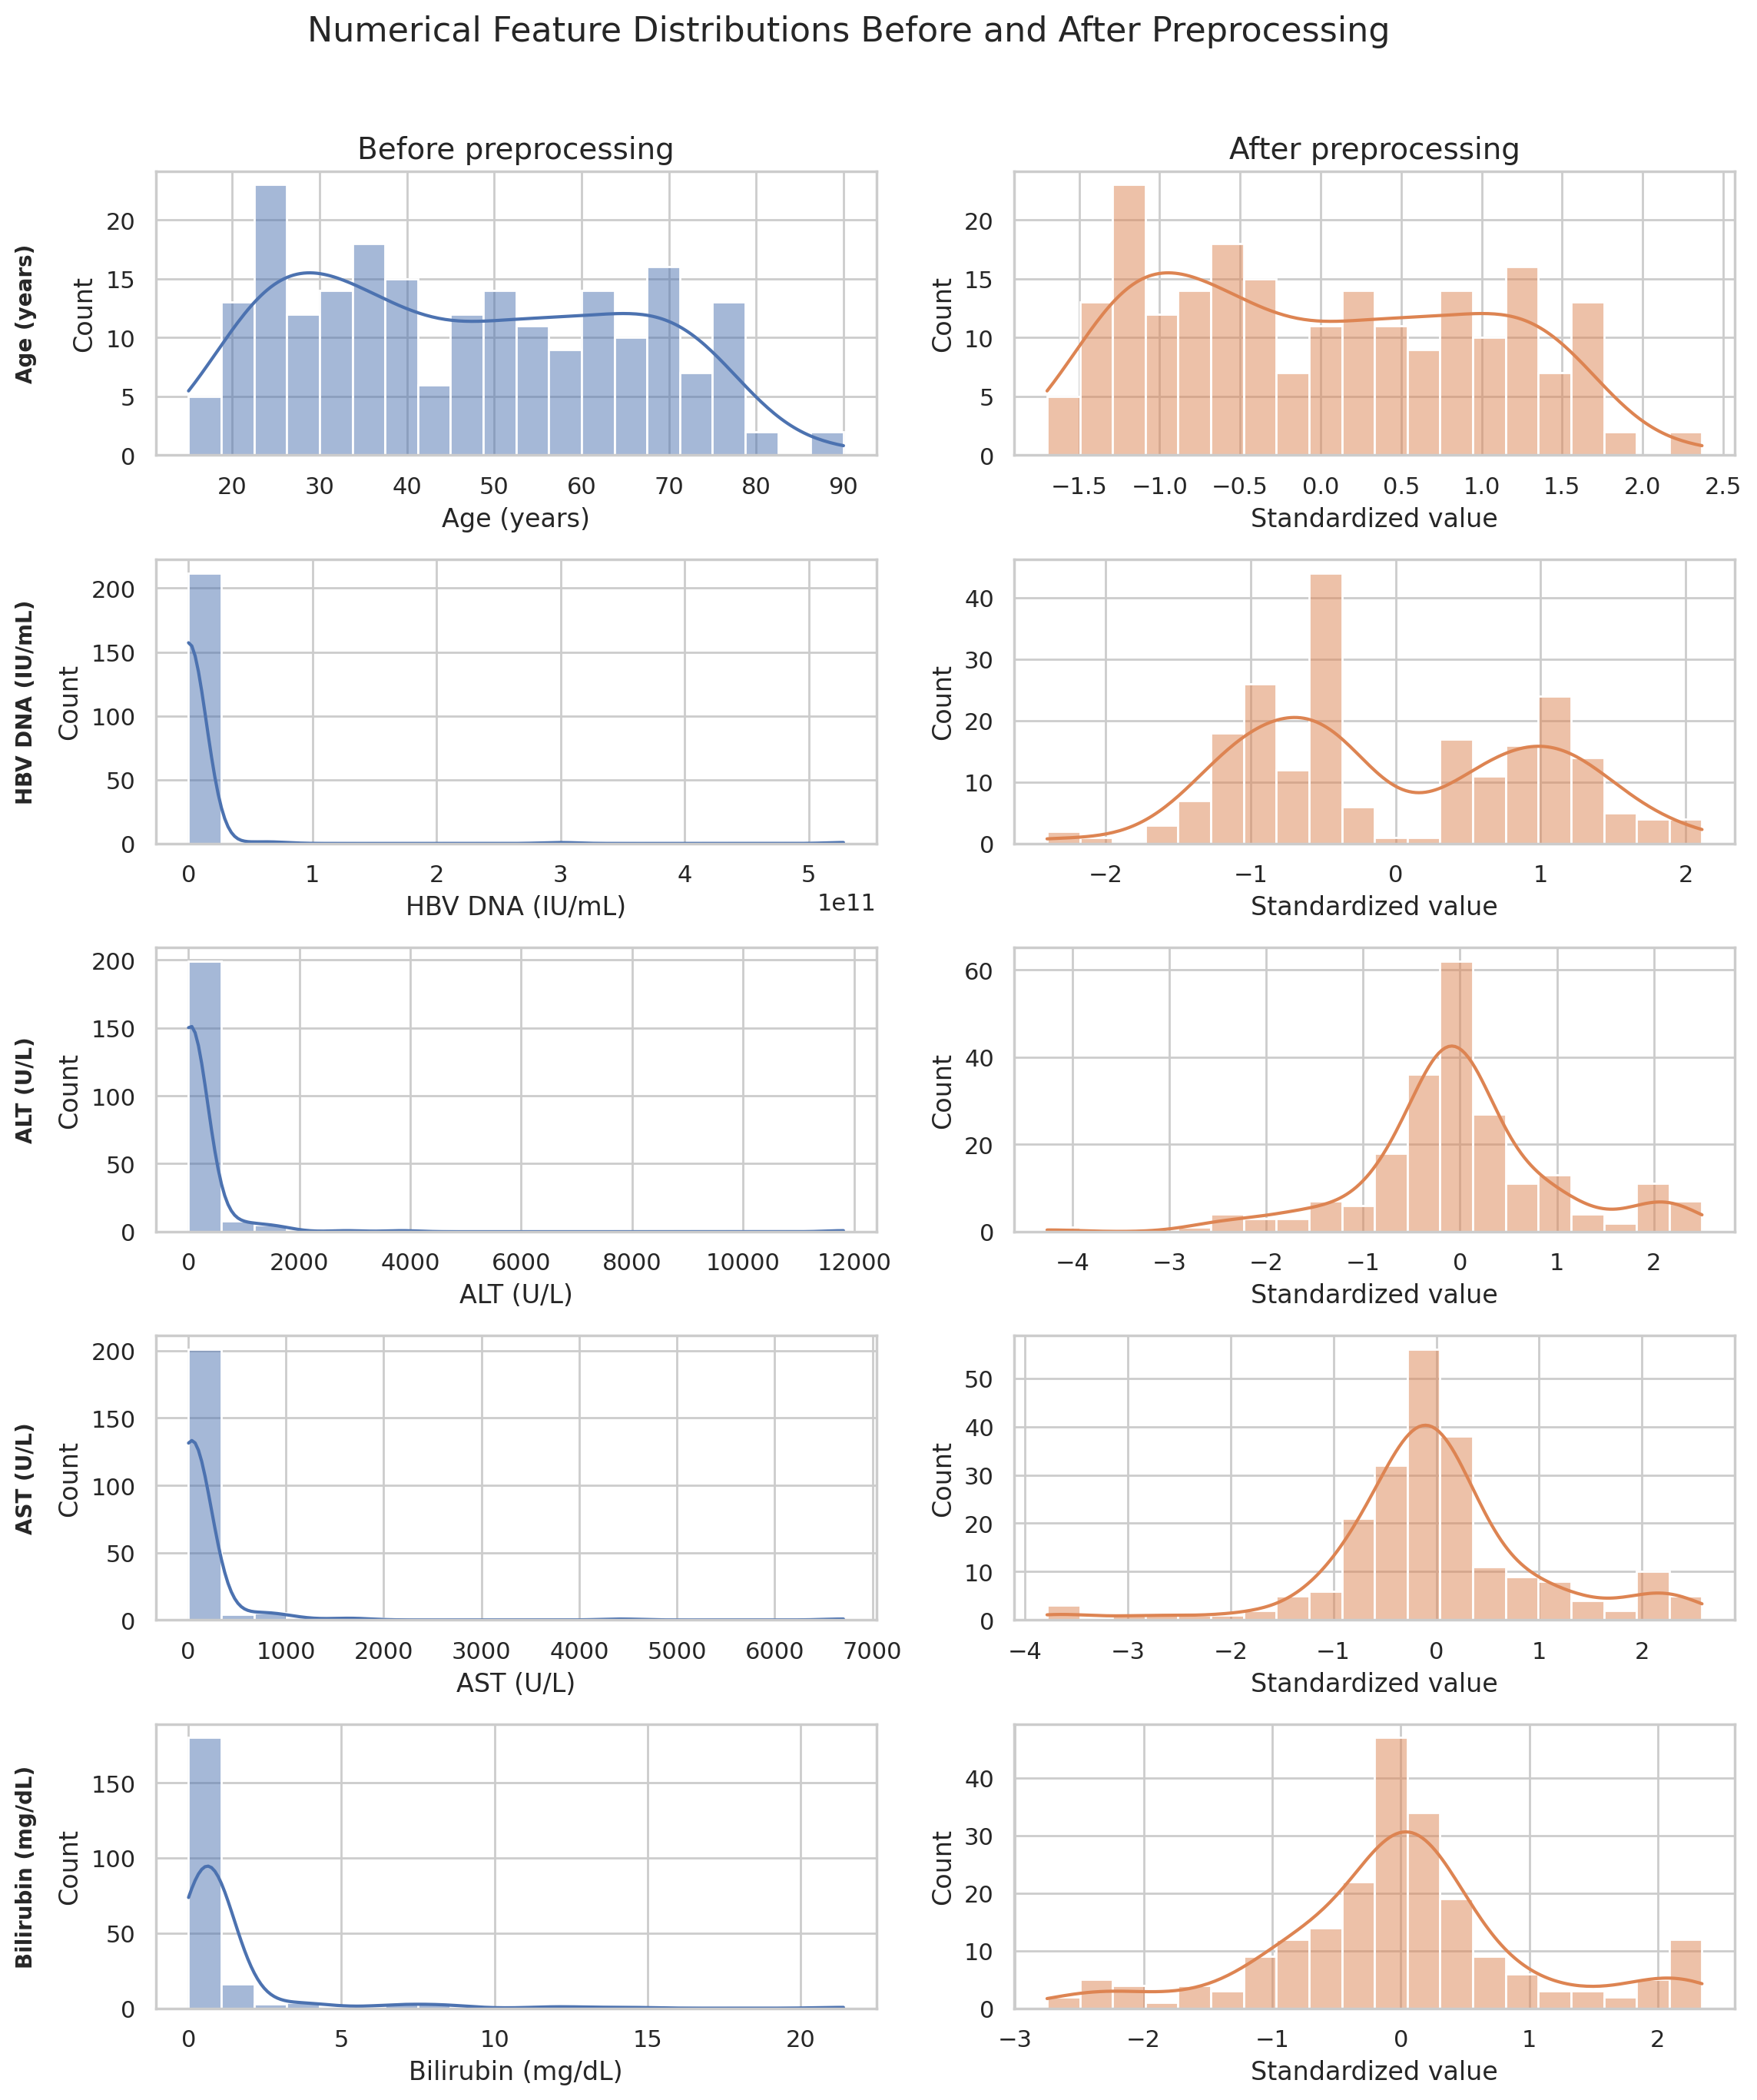

Saved revised Figure 2 to: /content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_2_revised_final.png


In [6]:
DISPLAY_NAMES = {
    'Age': 'Age (years)',
    'HBVDNA': 'HBV DNA (IU/mL)',
    'ALTLevel': 'ALT (U/L)',
    'ASTLevel': 'AST (U/L)',
    'Bilirubin': 'Bilirubin (mg/dL)'
}

sns.set_theme(style='whitegrid')
n_features = len(EDA_NUM_COLS)
fig, axes = plt.subplots(n_features, 2, figsize=(12, 14), dpi=200)

for row, col in enumerate(EDA_NUM_COLS):
    sns.histplot(eda_df[col], kde=True, bins=20, color='#4C72B0', ax=axes[row, 0])
    axes[row, 0].set_xlabel(DISPLAY_NAMES[col])
    axes[row, 0].set_ylabel('Count')

    sns.histplot(eda_scaled_df[col], kde=True, bins=20, color='#DD8452', ax=axes[row, 1])
    axes[row, 1].set_xlabel('Standardized value')
    axes[row, 1].set_ylabel('Count')

    axes[row, 0].annotate(
        DISPLAY_NAMES[col], xy=(-0.18, 0.5), xycoords='axes fraction',
        rotation=90, ha='center', va='center', fontsize=10, fontweight='bold'
    )

axes[0, 0].set_title('Before preprocessing', fontsize=14)
axes[0, 1].set_title('After preprocessing', fontsize=14)
fig.suptitle('Numerical Feature Distributions Before and After Preprocessing', fontsize=16, y=0.995)
plt.tight_layout(rect=[0.04, 0.02, 1, 0.98])

figure_2_path = OUT_DIR / 'Figure_2_revised_final.png'
plt.savefig(figure_2_path, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()

print('Saved revised Figure 2 to:', figure_2_path)

## 7. Regenerate revised Figure 3

Each raw feature receives its own y-axis. For visualization only, the raw laboratory variables are displayed as log10(value + 1), while Age remains in years. Processed values are displayed on linear standardized scales. The analysed data are not removed, clipped, or changed.

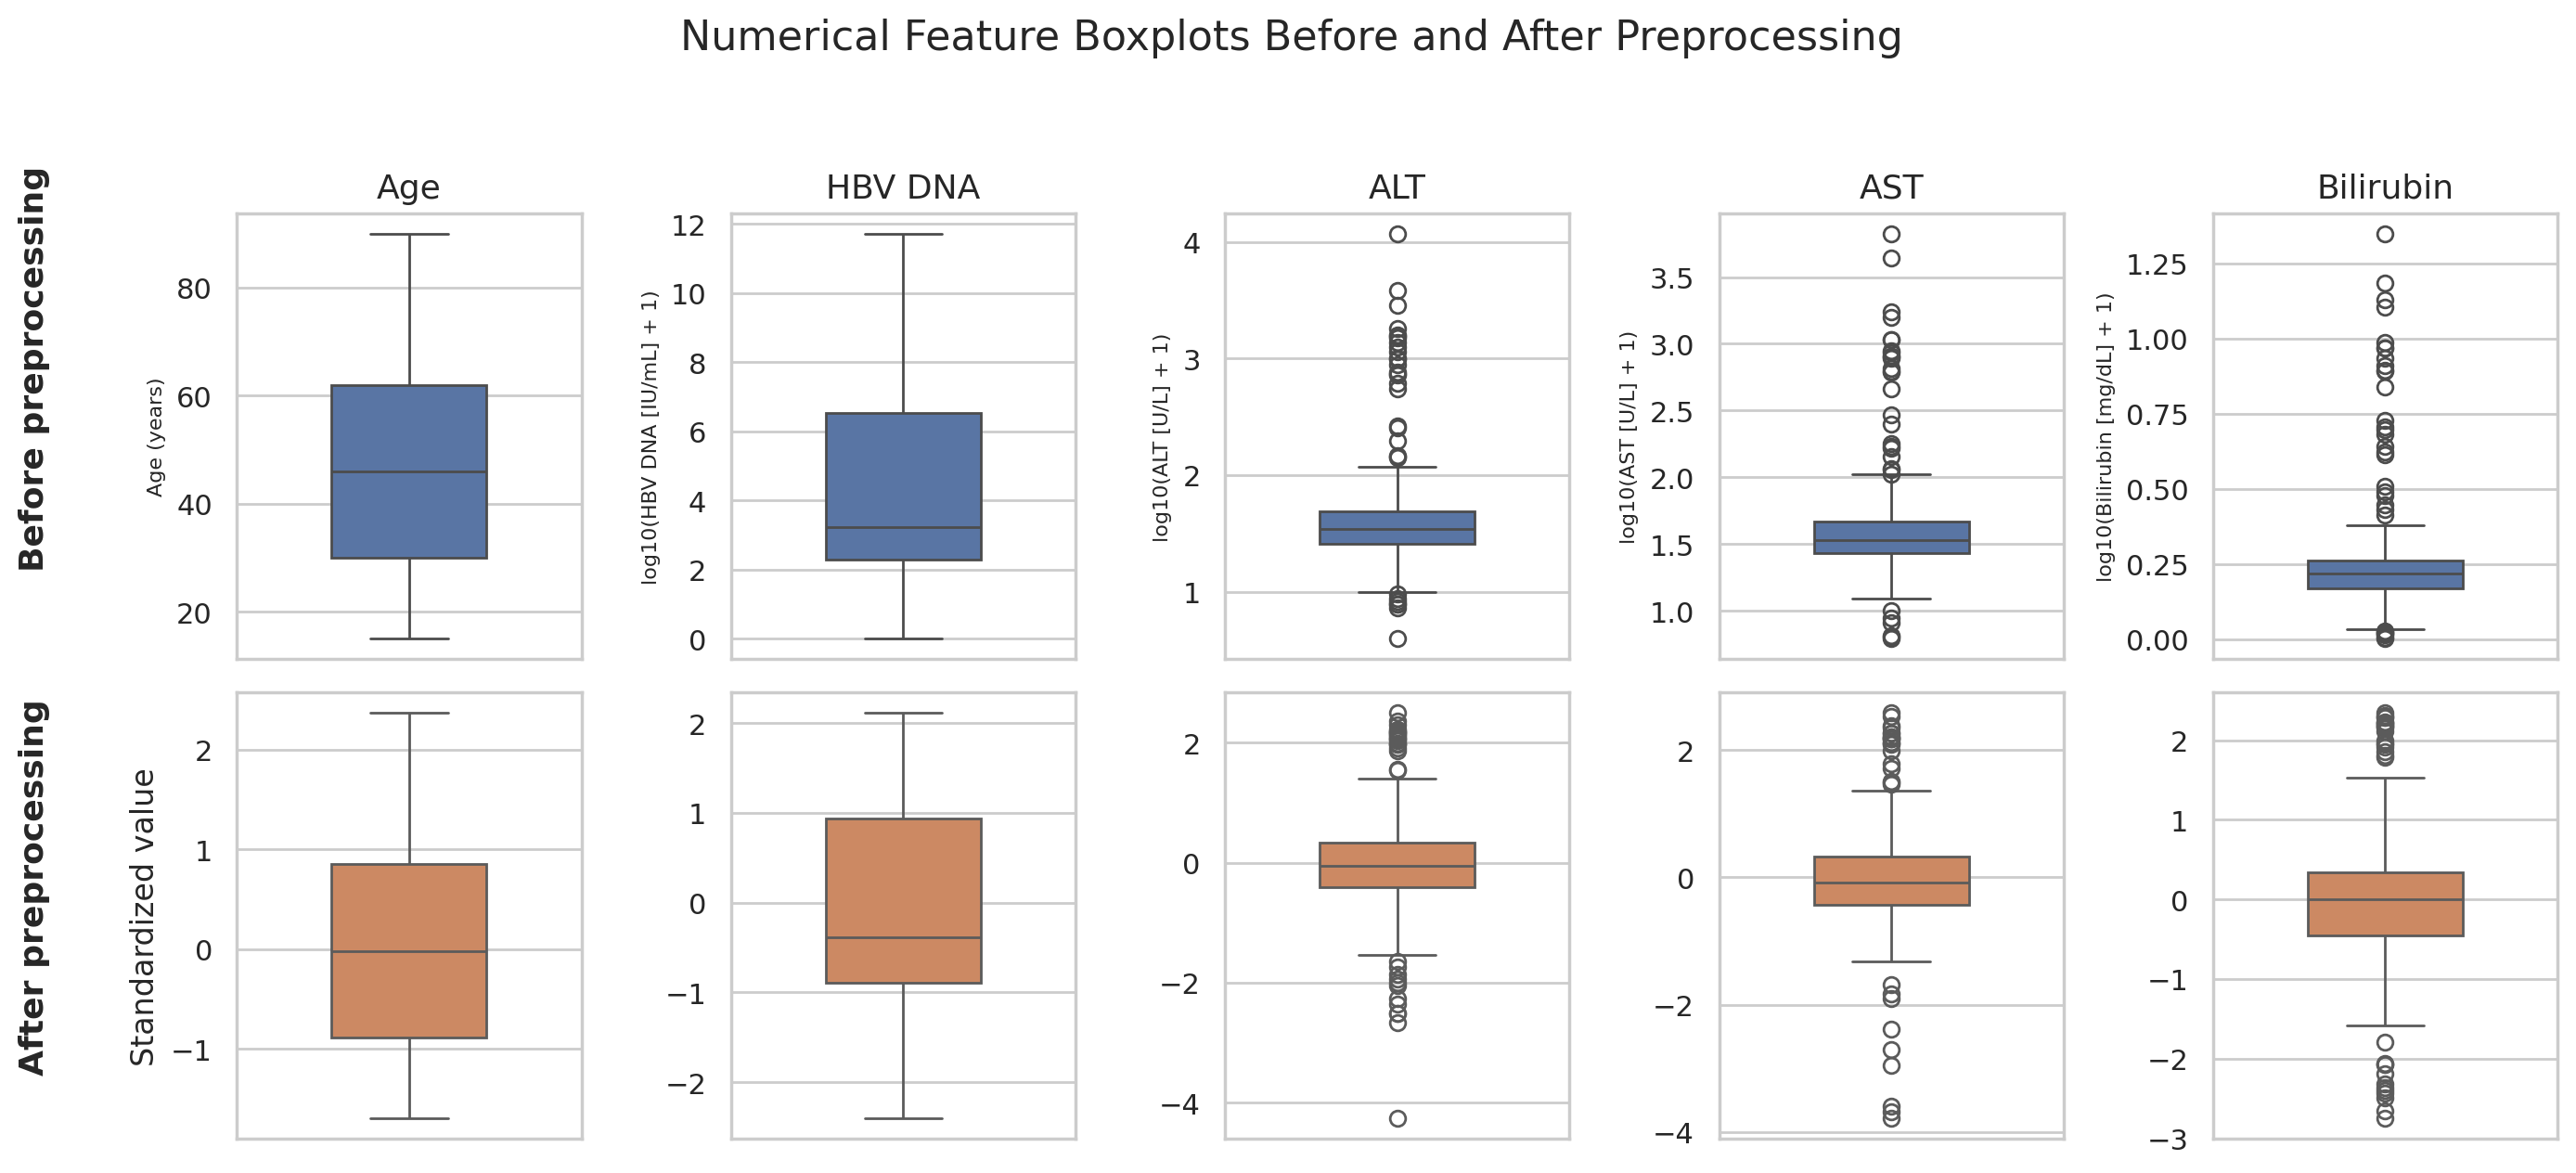

Saved revised Figure 3 to: /content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_3_revised_final.png


In [7]:
DISPLAY_NAMES = {'Age': 'Age', 'HBVDNA': 'HBV DNA', 'ALTLevel': 'ALT', 'ASTLevel': 'AST', 'Bilirubin': 'Bilirubin'}
RAW_AXIS_LABELS = {
    'Age': 'Age (years)',
    'HBVDNA': 'log10(HBV DNA [IU/mL] + 1)',
    'ALTLevel': 'log10(ALT [U/L] + 1)',
    'ASTLevel': 'log10(AST [U/L] + 1)',
    'Bilirubin': 'log10(Bilirubin [mg/dL] + 1)'
}
lab_features = {'HBVDNA', 'ALTLevel', 'ASTLevel', 'Bilirubin'}
n_features = len(EDA_NUM_COLS)
fig, axes = plt.subplots(2, n_features, figsize=(14, 6.5), dpi=200)

for index, col in enumerate(EDA_NUM_COLS):
    raw_values = np.log10(eda_df[col].astype(float).clip(lower=0) + 1) if col in lab_features else eda_df[col].astype(float)
    sns.boxplot(y=raw_values, color='#4C72B0', width=0.45, ax=axes[0, index])
    axes[0, index].set_title(DISPLAY_NAMES[col], fontsize=13)
    axes[0, index].set_xlabel('')
    axes[0, index].set_ylabel(RAW_AXIS_LABELS[col], fontsize=8)

    sns.boxplot(y=eda_scaled_df[col], color='#DD8452', width=0.45, ax=axes[1, index])
    axes[1, index].set_xlabel('')
    axes[1, index].set_ylabel('Standardized value' if index == 0 else '')

fig.text(0.01, 0.70, 'Before preprocessing', rotation=90, va='center', fontsize=13, fontweight='bold')
fig.text(0.01, 0.27, 'After preprocessing', rotation=90, va='center', fontsize=13, fontweight='bold')
fig.suptitle('Numerical Feature Boxplots Before and After Preprocessing', fontsize=16, y=0.99)
plt.tight_layout(rect=[0.04, 0.02, 1, 0.95])

figure_3_path = OUT_DIR / 'Figure_3_revised_final.png'
plt.savefig(figure_3_path, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()

print('Saved revised Figure 3 to:', figure_3_path)

## 8. Confirm generated files

The two PNG files are saved in `/content/drive/MyDrive/HBV_RF_Final_Outputs`.

In [8]:
for generated_path in [figure_2_path, figure_3_path]:
    print(generated_path, '| exists:', generated_path.exists(), '| bytes:', generated_path.stat().st_size if generated_path.exists() else 0)

/content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_2_revised_final.png | exists: True | bytes: 385184
/content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_3_revised_final.png | exists: True | bytes: 203144


## 9. Final leakage-controlled model evaluation

This section performs fold-wise preprocessing and SMOTE, comparable hyperparameter tuning, multi-seed evaluation, validation-based threshold selection, statistical testing, and HBV DNA sensitivity analysis.

In [9]:
from scipy.stats import randint
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, brier_score_loss)
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
import shap

RANDOM_STATE = 42

def preprocess_fit_transform(train_df, valid_df=None, test_df=None):
    train_df = train_df.copy()
    valid_df = None if valid_df is None else valid_df.copy()
    test_df = None if test_df is None else test_df.copy()
    for col in NUM_COLS:
        median = train_df[col].median()
        train_df[col] = train_df[col].fillna(median)
        if valid_df is not None: valid_df[col] = valid_df[col].fillna(median)
        if test_df is not None: test_df[col] = test_df[col].fillna(median)
    for col in CAT_COLS:
        mode = train_df[col].mode()[0]
        train_df[col] = train_df[col].fillna(mode)
        if valid_df is not None: valid_df[col] = valid_df[col].fillna(mode)
        if test_df is not None: test_df[col] = test_df[col].fillna(mode)
    for col, mapping in ENCODING_MAPS.items():
        train_df[col] = train_df[col].map(mapping)
        if valid_df is not None: valid_df[col] = valid_df[col].map(mapping)
        if test_df is not None: test_df[col] = test_df[col].map(mapping)
    for col in NUM_COLS:
        if abs(skew(train_df[col].astype(float))) > 1:
            transformed, lam = boxcox(train_df[col].astype(float).values + 1.0)
            train_df[col] = transformed
            for frame in [valid_df, test_df]:
                if frame is not None:
                    values = frame[col].astype(float).values + 1.0
                    frame[col] = np.log(values) if abs(lam) < 1e-8 else (np.power(values, lam) - 1) / lam
    scaler = StandardScaler()
    train_df[NUM_COLS] = scaler.fit_transform(train_df[NUM_COLS])
    if valid_df is not None: valid_df[NUM_COLS] = scaler.transform(valid_df[NUM_COLS])
    if test_df is not None: test_df[NUM_COLS] = scaler.transform(test_df[NUM_COLS])
    return train_df, valid_df, test_df

def choose_threshold(y_true, probabilities):
    rows = []
    for threshold in np.arange(0.30, 0.71, 0.01):
        predictions = (probabilities >= threshold).astype(int)
        accuracy = accuracy_score(y_true, predictions)
        f1 = f1_score(y_true, predictions, zero_division=0)
        rows.append((threshold, accuracy, f1, accuracy + f1))
    return max(rows, key=lambda row: row[3])[0]

def threshold_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall_Sensitivity': recall_score(y_true, predictions, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) else np.nan,
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'Brier': brier_score_loss(y_true, probabilities),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer
from scipy.stats import loguniform, uniform, t, wilcoxon
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

FINAL_SEEDS = [11, 21, 33, 42, 66, 77, 88, 99]
FINAL_FEATURES = ['HBVDNA', 'ALTLevel', 'ASTLevel', 'LossofAppetite',
                  'AbdominalPain', 'Age', 'VomitingFrequency']

class FoldClinicalPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features

    def _normalise_categories(self, frame):
        frame = frame.copy()
        for col in [c for c in CAT_COLS if c in frame.columns]:
            frame[col] = frame[col].where(frame[col].isna(), frame[col].astype(str).str.strip())
            if col == 'Gender':
                frame[col] = frame[col].where(frame[col].isna(), frame[col].str.upper())
            else:
                frame[col] = frame[col].where(frame[col].isna(), frame[col].str.lower())
        return frame

    def fit(self, X, y=None):
        frame = self._normalise_categories(pd.DataFrame(X).copy())
        self.numeric_features_ = [c for c in NUM_COLS if c in self.features]
        self.categorical_features_ = [c for c in CAT_COLS if c in self.features]
        self.medians_ = {c: frame[c].median() for c in self.numeric_features_}
        self.modes_ = {c: frame[c].mode(dropna=True).iloc[0] for c in self.categorical_features_}
        transformed = frame[self.features].copy()
        for c in self.numeric_features_:
            transformed[c] = pd.to_numeric(transformed[c], errors='coerce').fillna(self.medians_[c])
        for c in self.categorical_features_:
            transformed[c] = transformed[c].fillna(self.modes_[c]).map(ENCODING_MAPS[c])
        self.boxcox_lambdas_ = {}
        for c in self.numeric_features_:
            values = transformed[c].astype(float).to_numpy()
            if abs(skew(values)) > 1 and np.all(values + 1.0 > 0):
                values_transformed, lam = boxcox(values + 1.0)
                transformed[c] = values_transformed
                self.boxcox_lambdas_[c] = lam
        self.scaler_ = StandardScaler()
        if self.numeric_features_:
            self.scaler_.fit(transformed[self.numeric_features_])
        return self

    def transform(self, X):
        frame = self._normalise_categories(pd.DataFrame(X).copy())
        transformed = frame[self.features].copy()
        for c in self.numeric_features_:
            transformed[c] = pd.to_numeric(transformed[c], errors='coerce').fillna(self.medians_[c])
            if c in self.boxcox_lambdas_:
                values = transformed[c].astype(float).to_numpy() + 1.0
                lam = self.boxcox_lambdas_[c]
                transformed[c] = np.log(values) if abs(lam) < 1e-8 else (np.power(values, lam) - 1.0) / lam
        for c in self.categorical_features_:
            transformed[c] = transformed[c].fillna(self.modes_[c]).map(ENCODING_MAPS[c])
        if self.numeric_features_:
            transformed[self.numeric_features_] = self.scaler_.transform(transformed[self.numeric_features_])
        if transformed.isna().any().any():
            raise ValueError('Unmapped or missing values remain after fold preprocessing.')
        return transformed[self.features].astype(float).to_numpy()

def make_fold_pipeline(features, estimator, seed=42):
    return ImbPipeline([
        ('preprocess', FoldClinicalPreprocessor(features)),
        ('smote', SMOTE(random_state=seed, k_neighbors=5)),
        ('model', estimator)
    ])

def raw_xy(frame):
    X = frame.drop(columns=[TARGET_COL, 'Albumin'], errors='ignore').copy()
    y = frame[TARGET_COL].replace({'Negative': 0, 'Positive': 1,
                                   'negative': 0, 'positive': 1}).astype(int)
    return X, y

def metric_row(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'Threshold': float(threshold),
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) else np.nan,
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'Brier': brier_score_loss(y_true, probabilities),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

def validation_threshold(y_true, probabilities):
    candidates = []
    for threshold in np.arange(0.30, 0.71, 0.01):
        row = metric_row(y_true, probabilities, threshold)
        candidates.append((threshold, row['Accuracy'] + row['F1'], row['ROC_AUC']))
    return sorted(candidates, key=lambda item: (item[1], item[2]), reverse=True)[0][0]

MODEL_SPECS = {
    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {'model__n_estimators': randint(200, 1001), 'model__max_depth': [None, 4, 6, 8, 10, 12, 15],
         'model__min_samples_split': randint(2, 12), 'model__min_samples_leaf': randint(1, 6),
         'model__max_features': ['sqrt', 'log2', None], 'model__class_weight': [None, 'balanced']}
    ),
    'Logistic Regression': (
        LogisticRegression(max_iter=5000, solver='liblinear', random_state=42),
        {'model__C': loguniform(1e-3, 1e3), 'model__penalty': ['l1', 'l2'],
         'model__class_weight': [None, 'balanced']}
    ),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [None, 3, 4, 5, 6, 8, 10, 12],
         'model__min_samples_split': randint(2, 15), 'model__min_samples_leaf': randint(1, 8),
         'model__class_weight': [None, 'balanced'], 'model__criterion': ['gini', 'entropy']}
    ),
    'Linear SVM': (
        SVC(kernel='linear', probability=True, random_state=42),
        {'model__C': loguniform(1e-3, 1e3), 'model__class_weight': [None, 'balanced']}
    ),
    'Naive Bayes': (
        GaussianNB(), {'model__var_smoothing': loguniform(1e-12, 1e-6)}
    ),
    'KNN': (
        KNeighborsClassifier(),
        {'model__n_neighbors': randint(3, 21), 'model__weights': ['uniform', 'distance'],
         'model__p': [1, 2], 'model__leaf_size': randint(15, 51)}
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=42),
        {'model__n_estimators': randint(50, 501), 'model__learning_rate': loguniform(0.01, 0.3),
         'model__max_depth': randint(1, 6), 'model__min_samples_split': randint(2, 12),
         'model__min_samples_leaf': randint(1, 8), 'model__subsample': uniform(0.6, 0.4)}
    )
}

print('Final leakage-controlled setup ready.')

Final leakage-controlled setup ready.


In [11]:
# Common seed-42 development split used only for comparable hyperparameter tuning
X_all, y_all = raw_xy(df)
X_outer_train_42, X_outer_test_42, y_outer_train_42, y_outer_test_42 = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)
X_dev_42, X_val_42, y_dev_42, y_val_42 = train_test_split(
    X_outer_train_42, y_outer_train_42, test_size=0.20,
    stratify=y_outer_train_42, random_state=42
)

tuned_pipelines = {}
tuning_rows = []
for model_name, (estimator, distributions) in MODEL_SPECS.items():
    print('Tuning:', model_name)
    pipeline = make_fold_pipeline(FINAL_FEATURES, clone(estimator), seed=42)
    search_final = RandomizedSearchCV(
        pipeline, distributions, n_iter=40, scoring='roc_auc',
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        random_state=42, n_jobs=-1, verbose=0, refit=True
    )
    search_final.fit(X_dev_42, y_dev_42)
    tuned_pipelines[model_name] = search_final.best_estimator_
    tuning_rows.append({'Model': model_name, 'Best_CV_ROC_AUC': search_final.best_score_,
                        'Best_parameters': str(search_final.best_params_)})

tuning_df_final = pd.DataFrame(tuning_rows)
display(tuning_df_final)
tuning_df_final.to_csv(OUT_DIR / 'FINAL_comparable_tuning_results.csv', index=False)
print('Comparable tuning complete.')

Tuning: Random Forest
Tuning: Logistic Regression
Tuning: Decision Tree
Tuning: Linear SVM
Tuning: Naive Bayes
Tuning: KNN
Tuning: Gradient Boosting


,Model,Best_CV_ROC_AUC,Best_parameters
0,Random Forest,0.987839,"{'model__class_weight': 'balanced', 'model__ma..."
1,Logistic Regression,0.982808,"{'model__C': np.float64(93.84800715909533), 'm..."
2,Decision Tree,0.964029,"{'model__class_weight': None, 'model__criterio..."
3,Linear SVM,0.979536,"{'model__C': np.float64(695.8780103230359), 'm..."
4,Naive Bayes,0.985922,{'model__var_smoothing': np.float64(1.76701694...
5,KNN,0.991319,"{'model__leaf_size': 21, 'model__n_neighbors':..."
6,Gradient Boosting,0.987875,{'model__learning_rate': np.float64(0.04246261...


Comparable tuning complete.


,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Brier,TN,FP,FN,TP,Seed,Model
0,0.35,0.931818,0.956522,0.916667,0.95,0.936170,0.961458,0.065684,19,1,2,22,11,HepatoXAI-RF
1,0.50,0.909091,0.954545,0.875000,0.95,0.913043,0.961458,0.065684,19,1,3,21,11,Tuned Random Forest (0.50)
2,0.50,0.977273,1.000000,0.958333,1.00,0.978723,0.993750,0.030928,20,0,1,23,11,Logistic Regression
3,0.50,0.886364,0.913043,0.875000,0.90,0.893617,0.930208,0.086490,18,2,3,21,11,Decision Tree
4,0.50,0.977273,1.000000,0.958333,1.00,0.978723,0.993750,0.050653,20,0,1,23,11,Linear SVM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,0.50,0.886364,0.880000,0.916667,0.85,0.897959,0.923958,0.089148,17,3,2,22,99,Decision Tree
60,0.50,0.840909,0.814815,0.916667,0.75,0.862745,0.952083,0.093587,15,5,2,22,99,Linear SVM
61,0.50,0.818182,1.000000,0.666667,1.00,0.800000,0.954167,0.179901,20,0,8,16,99,Naive Bayes
62,0.50,0.863636,0.846154,0.916667,0.80,0.880000,0.960417,0.080071,16,4,2,22,99,KNN


,Model,Metric,Mean,Std,CI95_Lower,CI95_Upper
0,HepatoXAI-RF,Accuracy,0.911932,0.035287,0.882431,0.941433
1,HepatoXAI-RF,Precision,0.920234,0.054222,0.874904,0.965565
2,HepatoXAI-RF,Recall,0.921875,0.026703,0.899551,0.944199
3,HepatoXAI-RF,Specificity,0.900000,0.075593,0.836803,0.963197
4,HepatoXAI-RF,F1,0.920074,0.029438,0.895463,0.944685
5,HepatoXAI-RF,ROC_AUC,0.972005,0.015841,0.958762,0.985249
6,HepatoXAI-RF,Brier,0.054515,0.019058,0.038582,0.070448
7,Tuned Random Forest (0.50),Accuracy,0.926136,0.035935,0.896094,0.956179
8,Tuned Random Forest (0.50),Precision,0.966535,0.030491,0.941044,0.992026
9,Tuned Random Forest (0.50),Recall,0.895833,0.049801,0.854198,0.937468


,Mean_predicted_probability,Observed_positive_fraction
0,0.019444,0.000000
1,0.141049,0.111111
2,0.637326,0.625000
3,0.980710,1.000000
4,0.999846,1.000000


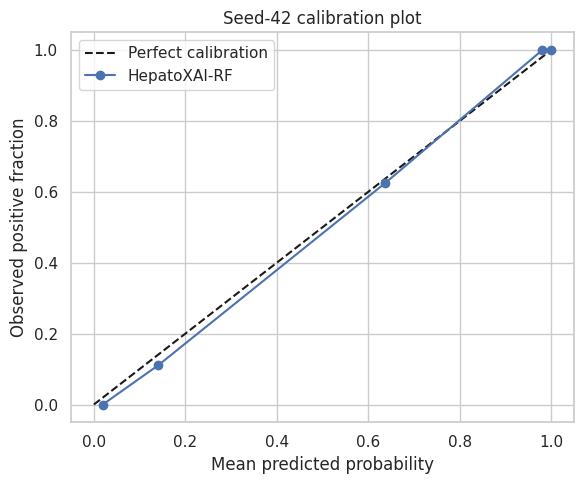

Multi-seed evaluation and uncertainty estimates complete.


In [12]:
# Eight-seed evaluation using the comparably tuned configurations
final_seed_rows = []
seed42_y_for_calibration = None
seed42_probability_for_calibration = None
for seed in FINAL_SEEDS:
    X_train_seed, X_test_seed, y_train_seed, y_test_seed = train_test_split(
        X_all, y_all, test_size=0.20, stratify=y_all, random_state=seed
    )
    X_dev_seed, X_val_seed, y_dev_seed, y_val_seed = train_test_split(
        X_train_seed, y_train_seed, test_size=0.20,
        stratify=y_train_seed, random_state=seed
    )

    # Proposed RF: threshold chosen only on this seed's validation subset
    proposed_dev = clone(tuned_pipelines['Random Forest'])
    proposed_dev.set_params(smote__random_state=seed, model__random_state=seed)
    proposed_dev.fit(X_dev_seed, y_dev_seed)
    val_probability = proposed_dev.predict_proba(X_val_seed)[:, 1]
    chosen_threshold = validation_threshold(y_val_seed, val_probability)

    proposed_final = clone(tuned_pipelines['Random Forest'])
    proposed_final.set_params(smote__random_state=seed, model__random_state=seed)
    proposed_final.fit(X_train_seed, y_train_seed)
    proposed_probability = proposed_final.predict_proba(X_test_seed)[:, 1]
    if seed == 42:
        seed42_y_for_calibration = y_test_seed.to_numpy()
        seed42_probability_for_calibration = proposed_probability.copy()
    proposed_row = metric_row(y_test_seed, proposed_probability, chosen_threshold)
    proposed_row.update({'Seed': seed, 'Model': 'HepatoXAI-RF'})
    final_seed_rows.append(proposed_row)

    # Same tuned RF at 0.50 is the explicit threshold control
    control_row = metric_row(y_test_seed, proposed_probability, 0.50)
    control_row.update({'Seed': seed, 'Model': 'Tuned Random Forest (0.50)'})
    final_seed_rows.append(control_row)

    # Other comparably tuned algorithm families use the common 0.50 threshold
    for model_name in [m for m in MODEL_SPECS if m != 'Random Forest']:
        fitted = clone(tuned_pipelines[model_name])
        fitted.set_params(smote__random_state=seed)
        if 'model__random_state' in fitted.get_params():
            fitted.set_params(model__random_state=seed)
        fitted.fit(X_train_seed, y_train_seed)
        probability = fitted.predict_proba(X_test_seed)[:, 1]
        row = metric_row(y_test_seed, probability, 0.50)
        row.update({'Seed': seed, 'Model': model_name})
        final_seed_rows.append(row)

final_seed_df = pd.DataFrame(final_seed_rows)
display(final_seed_df)
final_seed_df.to_csv(OUT_DIR / 'FINAL_multiseed_results.csv', index=False)

summary_rows = []
for model_name, group in final_seed_df.groupby('Model', sort=False):
    for metric in ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'Brier']:
        values = group[metric].astype(float)
        mean = values.mean()
        std = values.std(ddof=1)
        margin = t.ppf(0.975, len(values) - 1) * std / np.sqrt(len(values))
        summary_rows.append({'Model': model_name, 'Metric': metric, 'Mean': mean,
                             'Std': std, 'CI95_Lower': mean - margin, 'CI95_Upper': mean + margin})
final_summary_df = pd.DataFrame(summary_rows)
display(final_summary_df)
final_summary_df.to_csv(OUT_DIR / 'FINAL_multiseed_summary_with_95CI.csv', index=False)

# Seed-42 reliability table and calibration plot
fraction_positive, mean_predicted = calibration_curve(
    seed42_y_for_calibration, seed42_probability_for_calibration,
    n_bins=5, strategy='quantile'
)
calibration_df_final = pd.DataFrame({
    'Mean_predicted_probability': mean_predicted,
    'Observed_positive_fraction': fraction_positive
})
display(calibration_df_final)
calibration_df_final.to_csv(OUT_DIR / 'FINAL_seed42_calibration_bins.csv', index=False)
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
plt.plot(mean_predicted, fraction_positive, marker='o', label='HepatoXAI-RF')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed positive fraction')
plt.title('Seed-42 calibration plot')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'FINAL_seed42_calibration_plot.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()
print('Multi-seed evaluation and uncertainty estimates complete.')

In [13]:
# Paired Wilcoxon tests: HepatoXAI-RF versus every comparator across identical seeds
wilcoxon_rows = []
proposed_by_seed = final_seed_df[final_seed_df['Model'] == 'HepatoXAI-RF'].set_index('Seed')
for comparator in [m for m in final_seed_df['Model'].unique() if m != 'HepatoXAI-RF']:
    comparator_by_seed = final_seed_df[final_seed_df['Model'] == comparator].set_index('Seed')
    for metric in ['Accuracy', 'F1', 'ROC_AUC', 'Brier']:
        a = proposed_by_seed.loc[FINAL_SEEDS, metric].astype(float).to_numpy()
        b = comparator_by_seed.loc[FINAL_SEEDS, metric].astype(float).to_numpy()
        try:
            statistic, p_value = wilcoxon(a, b, alternative='two-sided', zero_method='wilcox')
        except ValueError:
            statistic, p_value = 0.0, 1.0
        wilcoxon_rows.append({'Comparator': comparator, 'Metric': metric,
                              'Statistic': statistic, 'P_value': p_value,
                              'Mean_difference': float(np.mean(a - b))})
wilcoxon_df = pd.DataFrame(wilcoxon_rows)
display(wilcoxon_df)
wilcoxon_df.to_csv(OUT_DIR / 'FINAL_paired_wilcoxon_tests.csv', index=False)

# Definitive seed-42 threshold-control table
seed42_control_df = final_seed_df[(final_seed_df['Seed'] == 42) &
    (final_seed_df['Model'].isin(['HepatoXAI-RF', 'Tuned Random Forest (0.50)']))].copy()
display(seed42_control_df)
seed42_control_df.to_csv(OUT_DIR / 'FINAL_seed42_threshold_control.csv', index=False)
print('Paired tests and threshold control complete.')

,Comparator,Metric,Statistic,P_value,Mean_difference
0,Tuned Random Forest (0.50),Accuracy,5.0,0.171875,-0.014205
1,Tuned Random Forest (0.50),F1,11.0,0.671875,-0.009217
2,Tuned Random Forest (0.50),ROC_AUC,0.0,1.000000,0.000000
3,Tuned Random Forest (0.50),Brier,0.0,1.000000,0.000000
4,Logistic Regression,Accuracy,9.0,0.875000,-0.002841
5,Logistic Regression,F1,14.0,1.000000,-0.001570
6,Logistic Regression,ROC_AUC,17.0,0.937500,0.000130
7,Logistic Regression,Brier,15.0,0.742188,-0.007987
8,Decision Tree,Accuracy,14.0,1.000000,0.002841
9,Decision Tree,F1,13.0,0.937500,0.003498


,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Brier,TN,FP,FN,TP,Seed,Model
24,0.34,0.909091,0.884615,0.958333,0.85,0.92000,0.98125,0.047489,17,3,1,23,42,HepatoXAI-RF
25,0.50,0.931818,0.956522,0.916667,0.95,0.93617,0.98125,0.047489,19,1,2,22,42,Tuned Random Forest (0.50)


Paired tests and threshold control complete.


In [14]:
# Definitive leakage-controlled HBV DNA sensitivity analysis on seed 42
def tune_and_test_configuration(label, features):
    rf_estimator, rf_distributions = MODEL_SPECS['Random Forest']
    pipeline = make_fold_pipeline(features, clone(rf_estimator), seed=42)
    search_configuration = RandomizedSearchCV(
        pipeline, rf_distributions, n_iter=40, scoring='roc_auc',
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        random_state=42, n_jobs=-1, verbose=0, refit=True
    )
    search_configuration.fit(X_dev_42, y_dev_42)
    validation_probability = search_configuration.best_estimator_.predict_proba(X_val_42)[:, 1]
    threshold = validation_threshold(y_val_42, validation_probability)
    final_pipeline = clone(search_configuration.best_estimator_)
    final_pipeline.fit(X_outer_train_42, y_outer_train_42)
    test_probability = final_pipeline.predict_proba(X_outer_test_42)[:, 1]
    row = metric_row(y_outer_test_42, test_probability, threshold)
    row.update({'Configuration': label, 'Number_of_features': len(features),
                'Features': ', '.join(features),
                'Best_parameters': str(search_configuration.best_params_)})
    return row

final_circularity_df = pd.DataFrame([
    tune_and_test_configuration('Full seven-feature model', FINAL_FEATURES),
    tune_and_test_configuration('HBV DNA alone', ['HBVDNA']),
    tune_and_test_configuration('Model excluding HBV DNA', [f for f in FINAL_FEATURES if f != 'HBVDNA'])
])
display(final_circularity_df)
final_circularity_df.to_csv(OUT_DIR / 'FINAL_HBVDNA_sensitivity_analysis.csv', index=False)

print('FINAL comprehensive rerun finished.')
print('Use only files beginning with FINAL_ for manuscript revision.')
print('Output directory:', OUT_DIR)

,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Brier,TN,FP,FN,TP,Configuration,Number_of_features,Features,Best_parameters
0,0.34,0.909091,0.884615,0.958333,0.85,0.920000,0.981250,0.047489,17,3,1,23,Full seven-feature model,7,"HBVDNA, ALTLevel, ASTLevel, LossofAppetite, Ab...","{'model__class_weight': 'balanced', 'model__ma..."
1,0.48,0.931818,0.956522,0.916667,0.95,0.936170,0.952083,0.056397,19,1,2,22,HBV DNA alone,1,HBVDNA,"{'model__class_weight': None, 'model__max_dept..."
2,0.30,0.840909,0.814815,0.916667,0.75,0.862745,0.941667,0.096831,15,5,2,22,Model excluding HBV DNA,6,"ALTLevel, ASTLevel, LossofAppetite, AbdominalP...","{'model__class_weight': 'balanced', 'model__ma..."


FINAL comprehensive rerun finished.
Use only files beginning with FINAL_ for manuscript revision.
Output directory: /content/drive/MyDrive/HBV_RF_Final_Outputs


In [15]:
hepatoxai_seed_table = final_seed_df[
    final_seed_df["Model"] == "HepatoXAI-RF"
][[
    "Seed", "Threshold", "Accuracy", "Precision", "Recall",
    "Specificity", "F1", "ROC_AUC", "Brier"
]]

display(hepatoxai_seed_table)

,Seed,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Brier
0,11,0.35,0.931818,0.956522,0.916667,0.95,0.936170,0.961458,0.065684
8,21,0.43,0.931818,0.956522,0.916667,0.95,0.936170,0.981250,0.047283
16,33,0.48,0.909091,0.954545,0.875000,0.95,0.913043,0.962500,0.061258
24,42,0.34,0.909091,0.884615,0.958333,0.85,0.920000,0.981250,0.047489
32,66,0.30,0.886364,0.880000,0.916667,0.85,0.897959,0.950000,0.084999
40,77,0.30,0.931818,0.956522,0.916667,0.95,0.936170,0.987500,0.038932
48,88,0.30,0.954545,0.958333,0.958333,0.95,0.958333,0.993750,0.023714
56,99,0.30,0.840909,0.814815,0.916667,0.75,0.862745,0.958333,0.066759


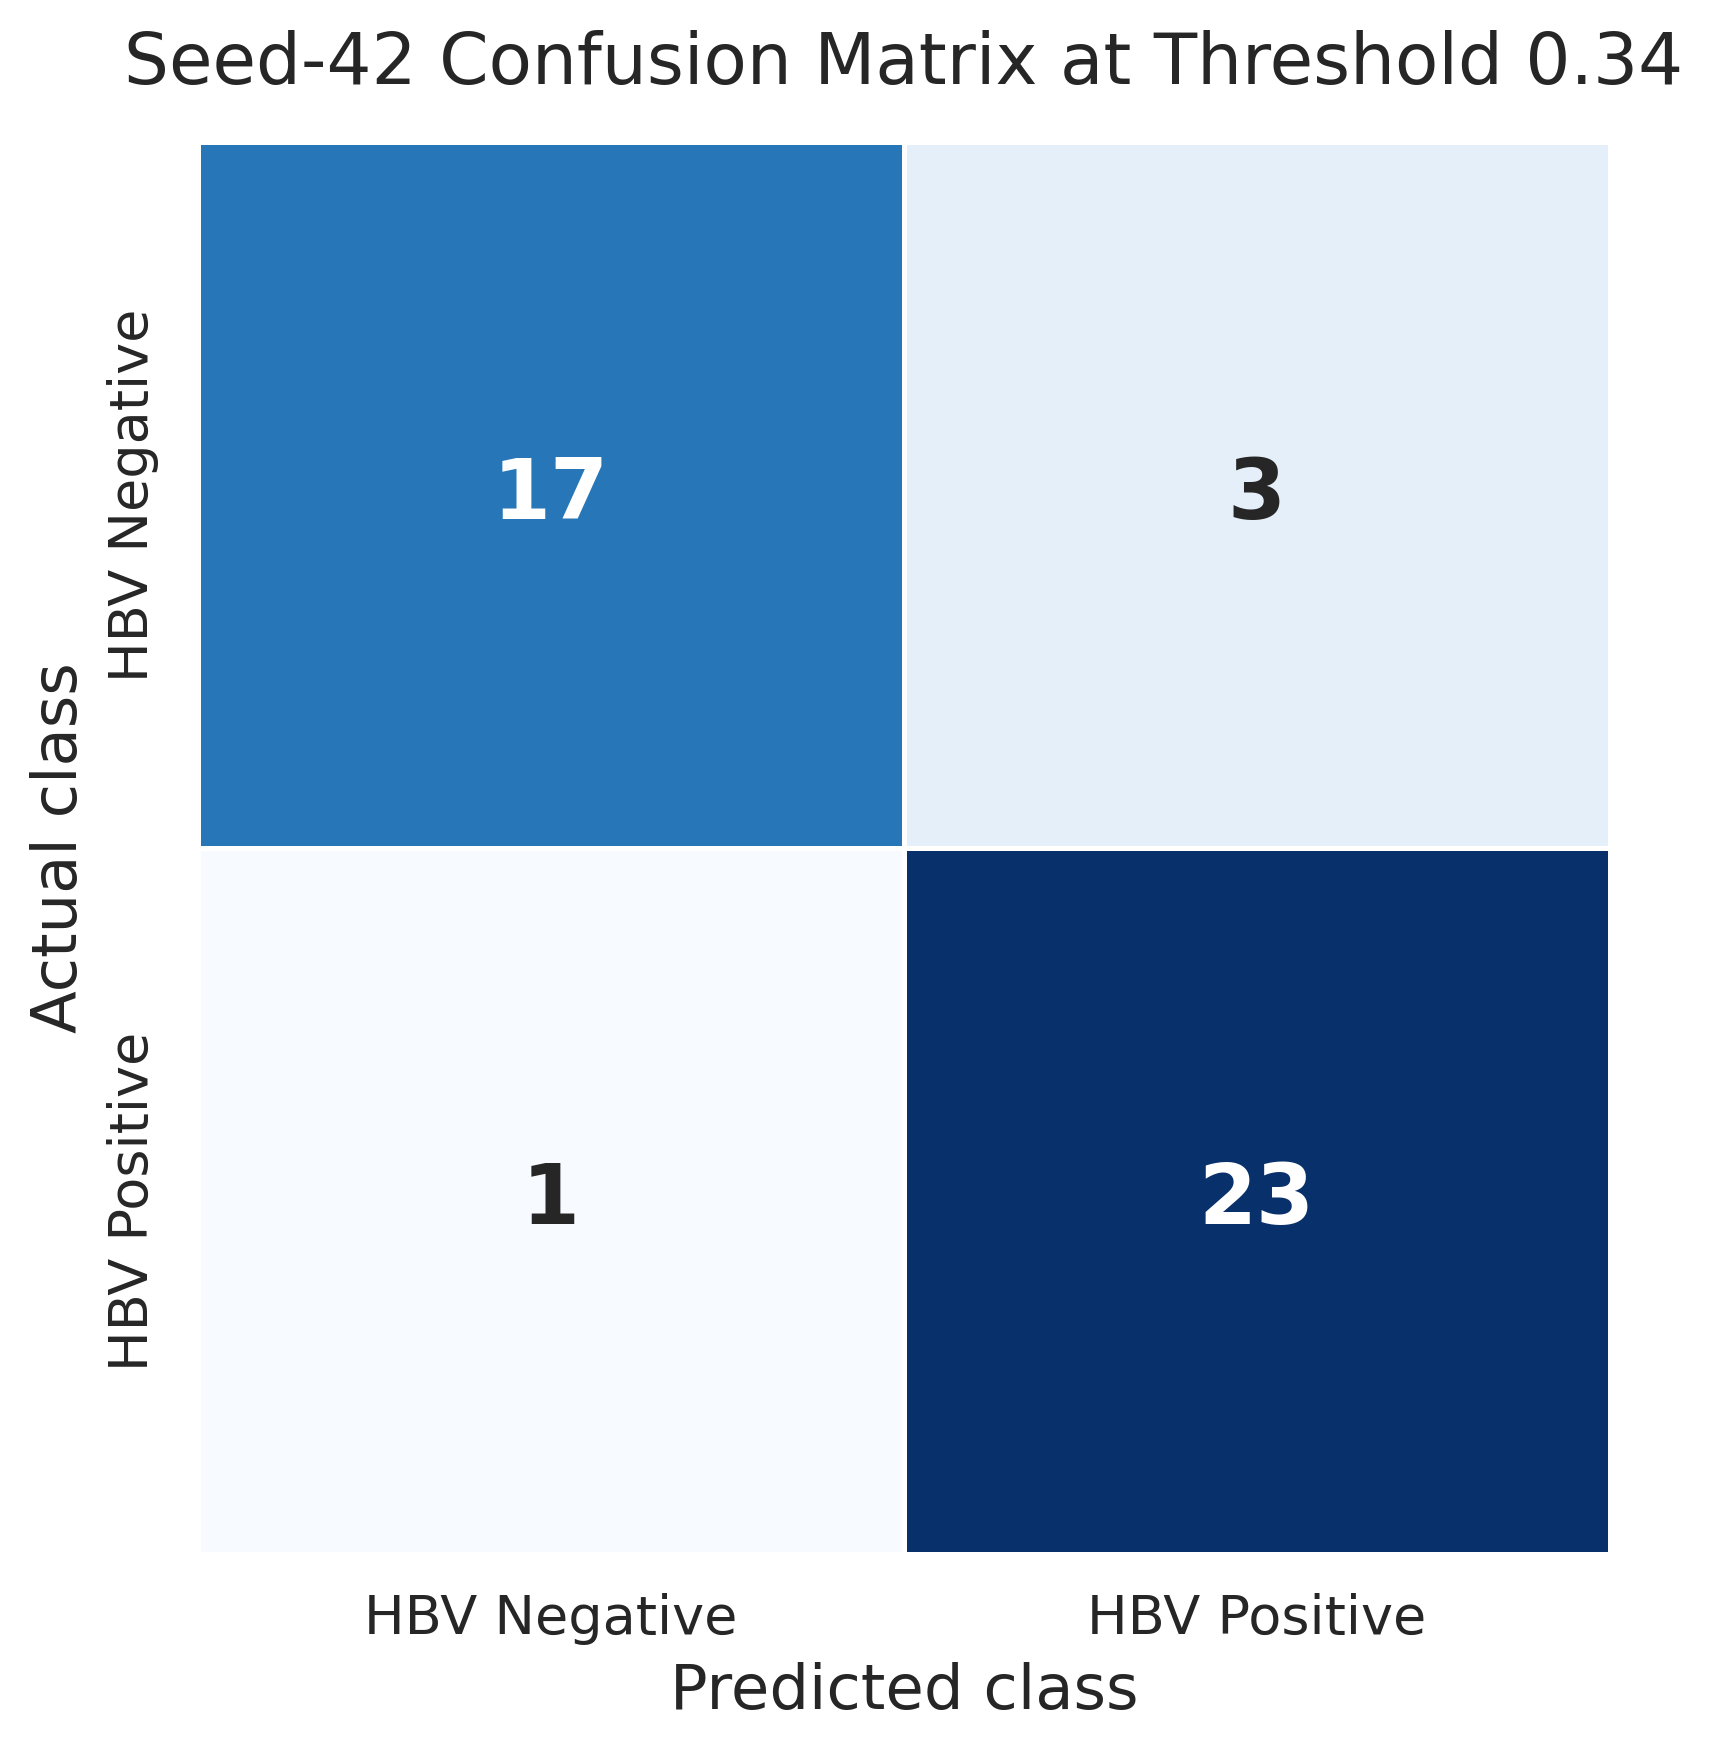

Saved: /content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_8_revised_full_HD.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

OUT_DIR = Path("/content/drive/MyDrive/HBV_RF_Final_Outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

cm = np.array([
    [17, 3],
    [1, 23]
])

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    square=True,
    linewidths=1.2,
    linecolor="white",
    xticklabels=["HBV Negative", "HBV Positive"],
    yticklabels=["HBV Negative", "HBV Positive"],
    annot_kws={"size": 20, "weight": "bold"},
    ax=ax
)

ax.set_xlabel("Predicted class", fontsize=15)
ax.set_ylabel("Actual class", fontsize=15)
ax.set_title(
    "Seed-42 Confusion Matrix at Threshold 0.34",
    fontsize=17,
    pad=14
)
ax.tick_params(axis="both", labelsize=13)

plt.tight_layout()

figure8_path = OUT_DIR / "Figure_8_revised_full_HD.png"
plt.savefig(
    figure8_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close()

print("Saved:", figure8_path)
files.download(str(figure8_path))

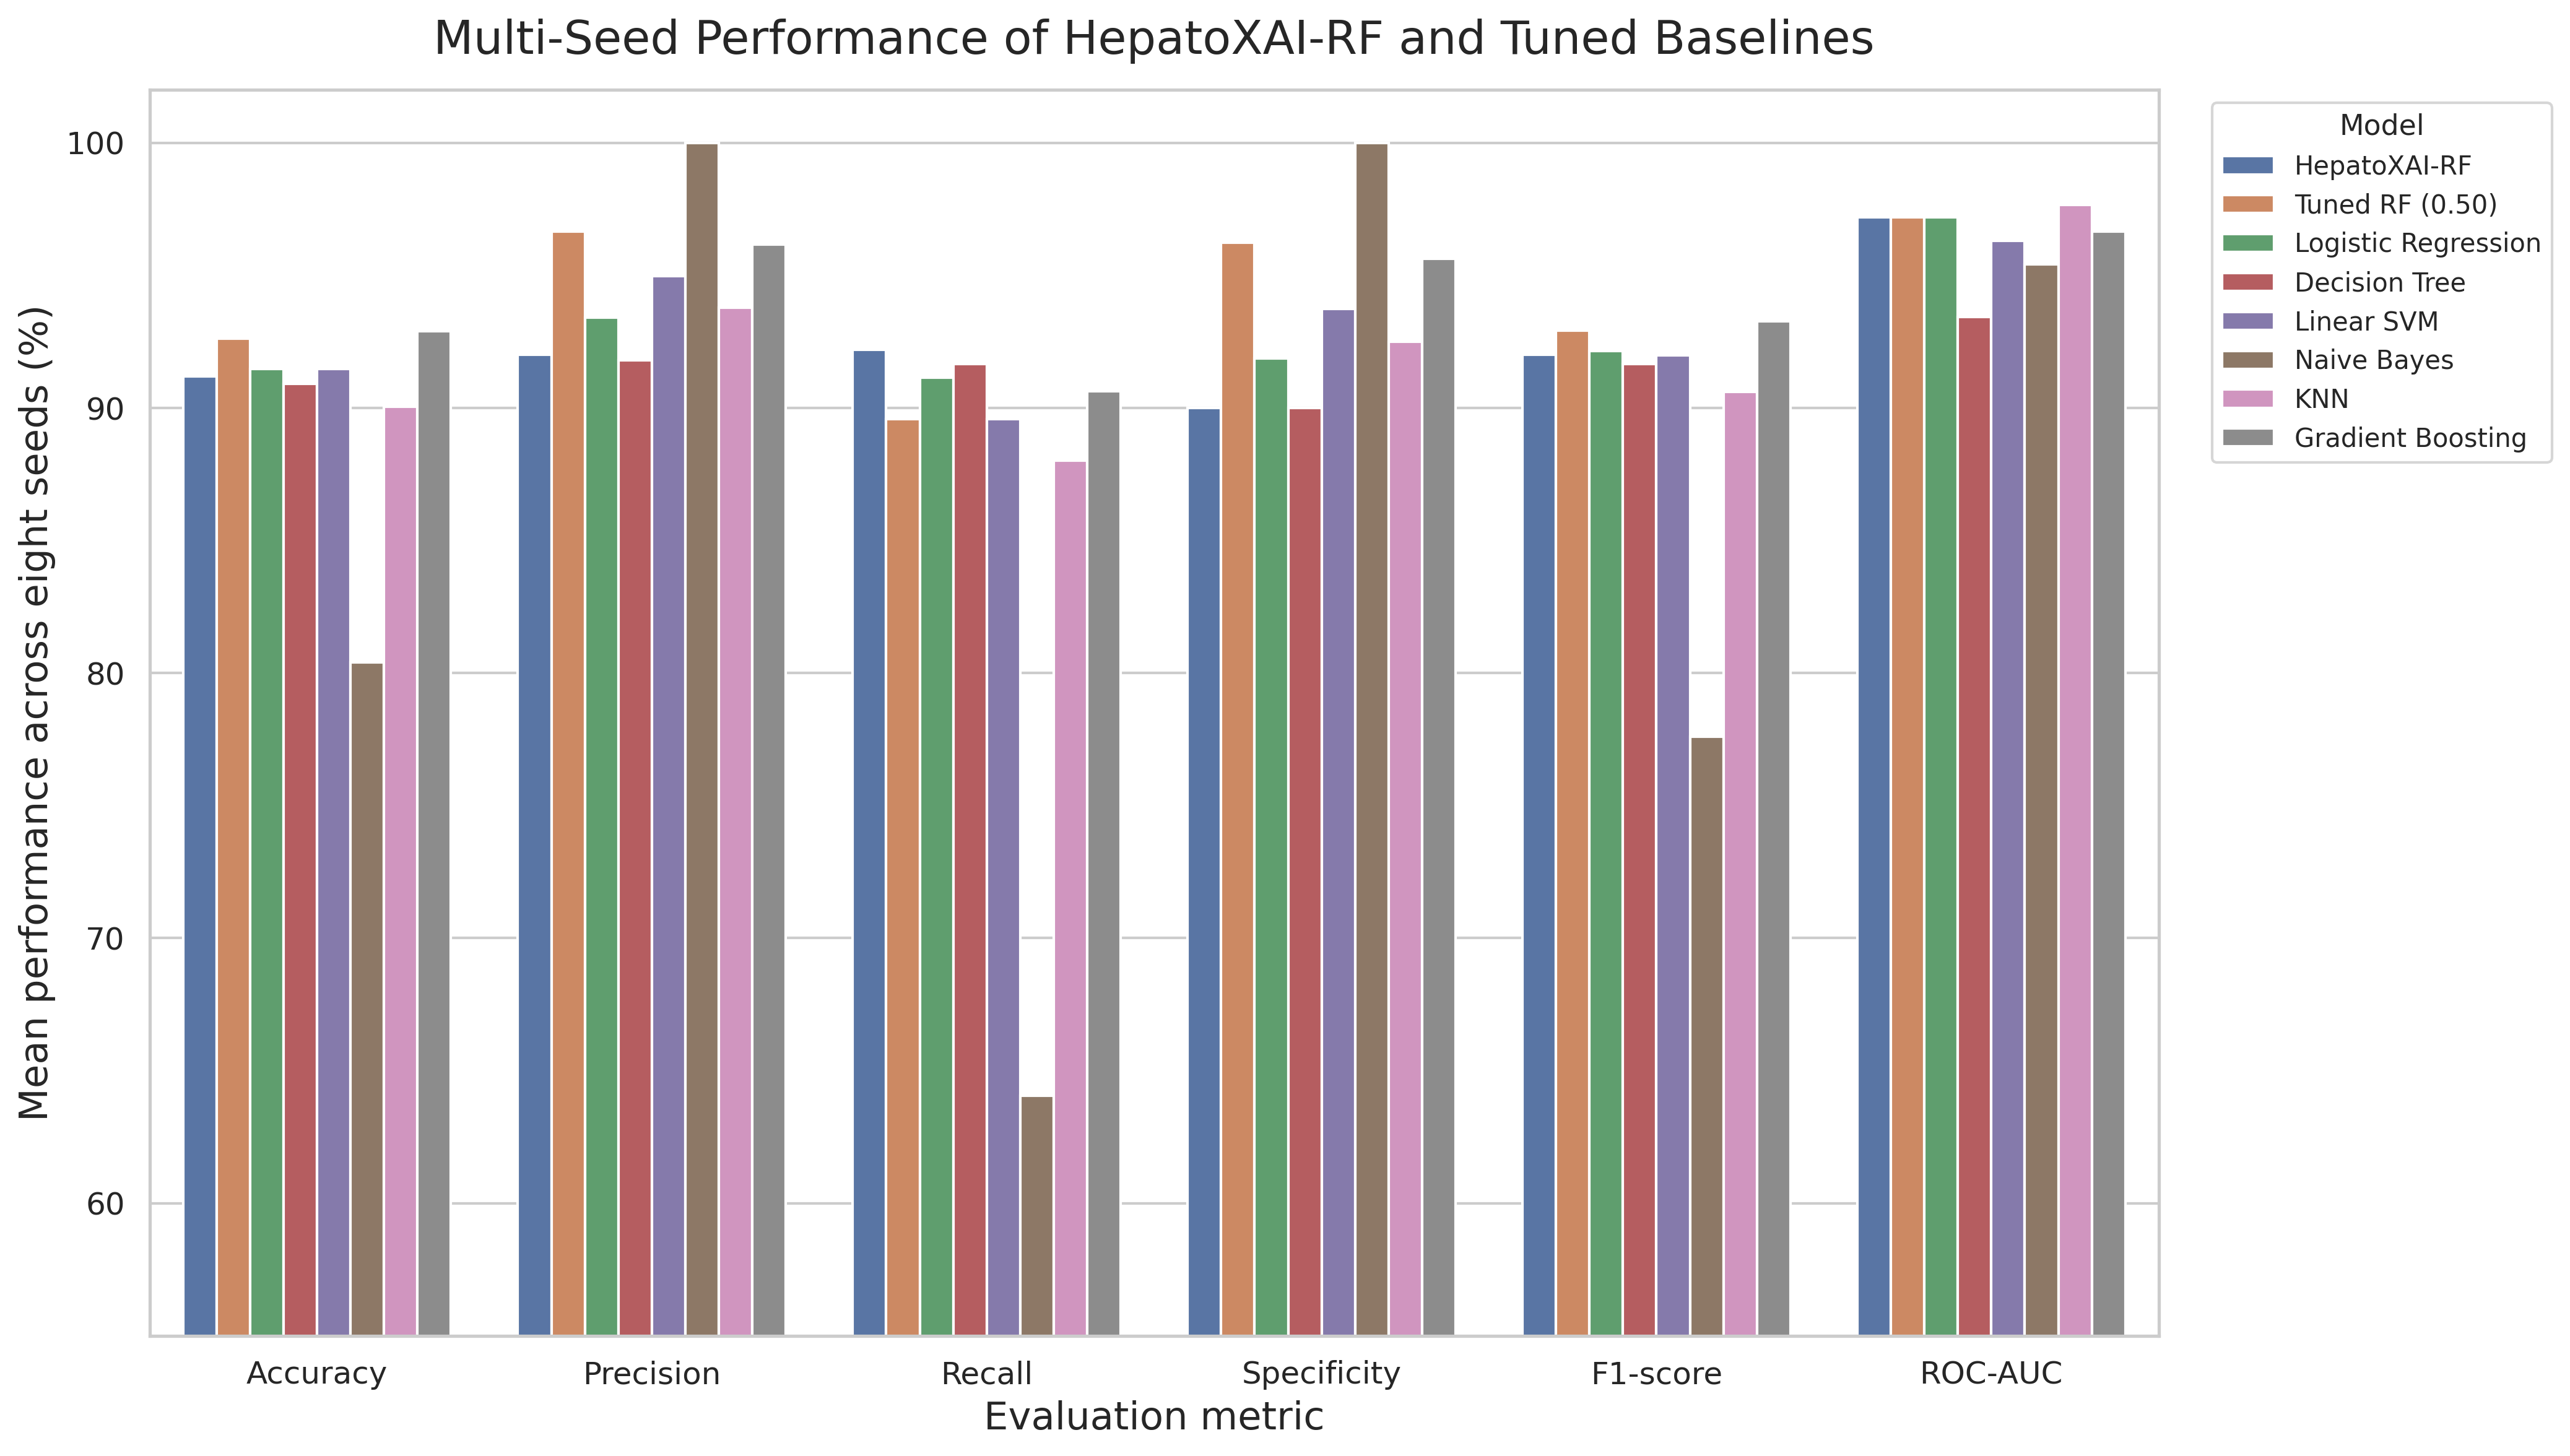

Saved: /content/drive/MyDrive/HBV_RF_Final_Outputs/Figure_14_revised_full_HD.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

OUT_DIR = Path("/content/drive/MyDrive/HBV_RF_Final_Outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

figure14_data = pd.DataFrame({
    "Model": [
        "HepatoXAI-RF",
        "Tuned RF (0.50)",
        "Logistic Regression",
        "Decision Tree",
        "Linear SVM",
        "Naive Bayes",
        "KNN",
        "Gradient Boosting"
    ],
    "Accuracy": [91.19, 92.61, 91.48, 90.91, 91.48, 80.40, 90.06, 92.90],
    "Precision": [92.02, 96.65, 93.42, 91.80, 94.98, 100.00, 93.79, 96.16],
    "Recall": [92.19, 89.58, 91.15, 91.67, 89.58, 64.06, 88.02, 90.63],
    "Specificity": [90.00, 96.25, 91.88, 90.00, 93.75, 100.00, 92.50, 95.63],
    "F1-score": [92.01, 92.93, 92.16, 91.66, 92.00, 77.61, 90.60, 93.27],
    "ROC-AUC": [97.20, 97.20, 97.19, 93.44, 96.30, 95.42, 97.66, 96.67]
})

plot_data = figure14_data.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Performance (%)"
)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(14, 8), dpi=300)

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Performance (%)",
    hue="Model",
    ax=ax
)

ax.set_ylim(55, 102)
ax.set_xlabel("Evaluation metric", fontsize=15)
ax.set_ylabel("Mean performance across eight seeds (%)", fontsize=15)
ax.set_title(
    "Multi-Seed Performance of HepatoXAI-RF and Tuned Baselines",
    fontsize=18,
    pad=14
)
ax.tick_params(axis="both", labelsize=12)
ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()

figure14_path = OUT_DIR / "Figure_14_revised_full_HD.png"
plt.savefig(
    figure14_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close()

print("Saved:", figure14_path)
files.download(str(figure14_path))


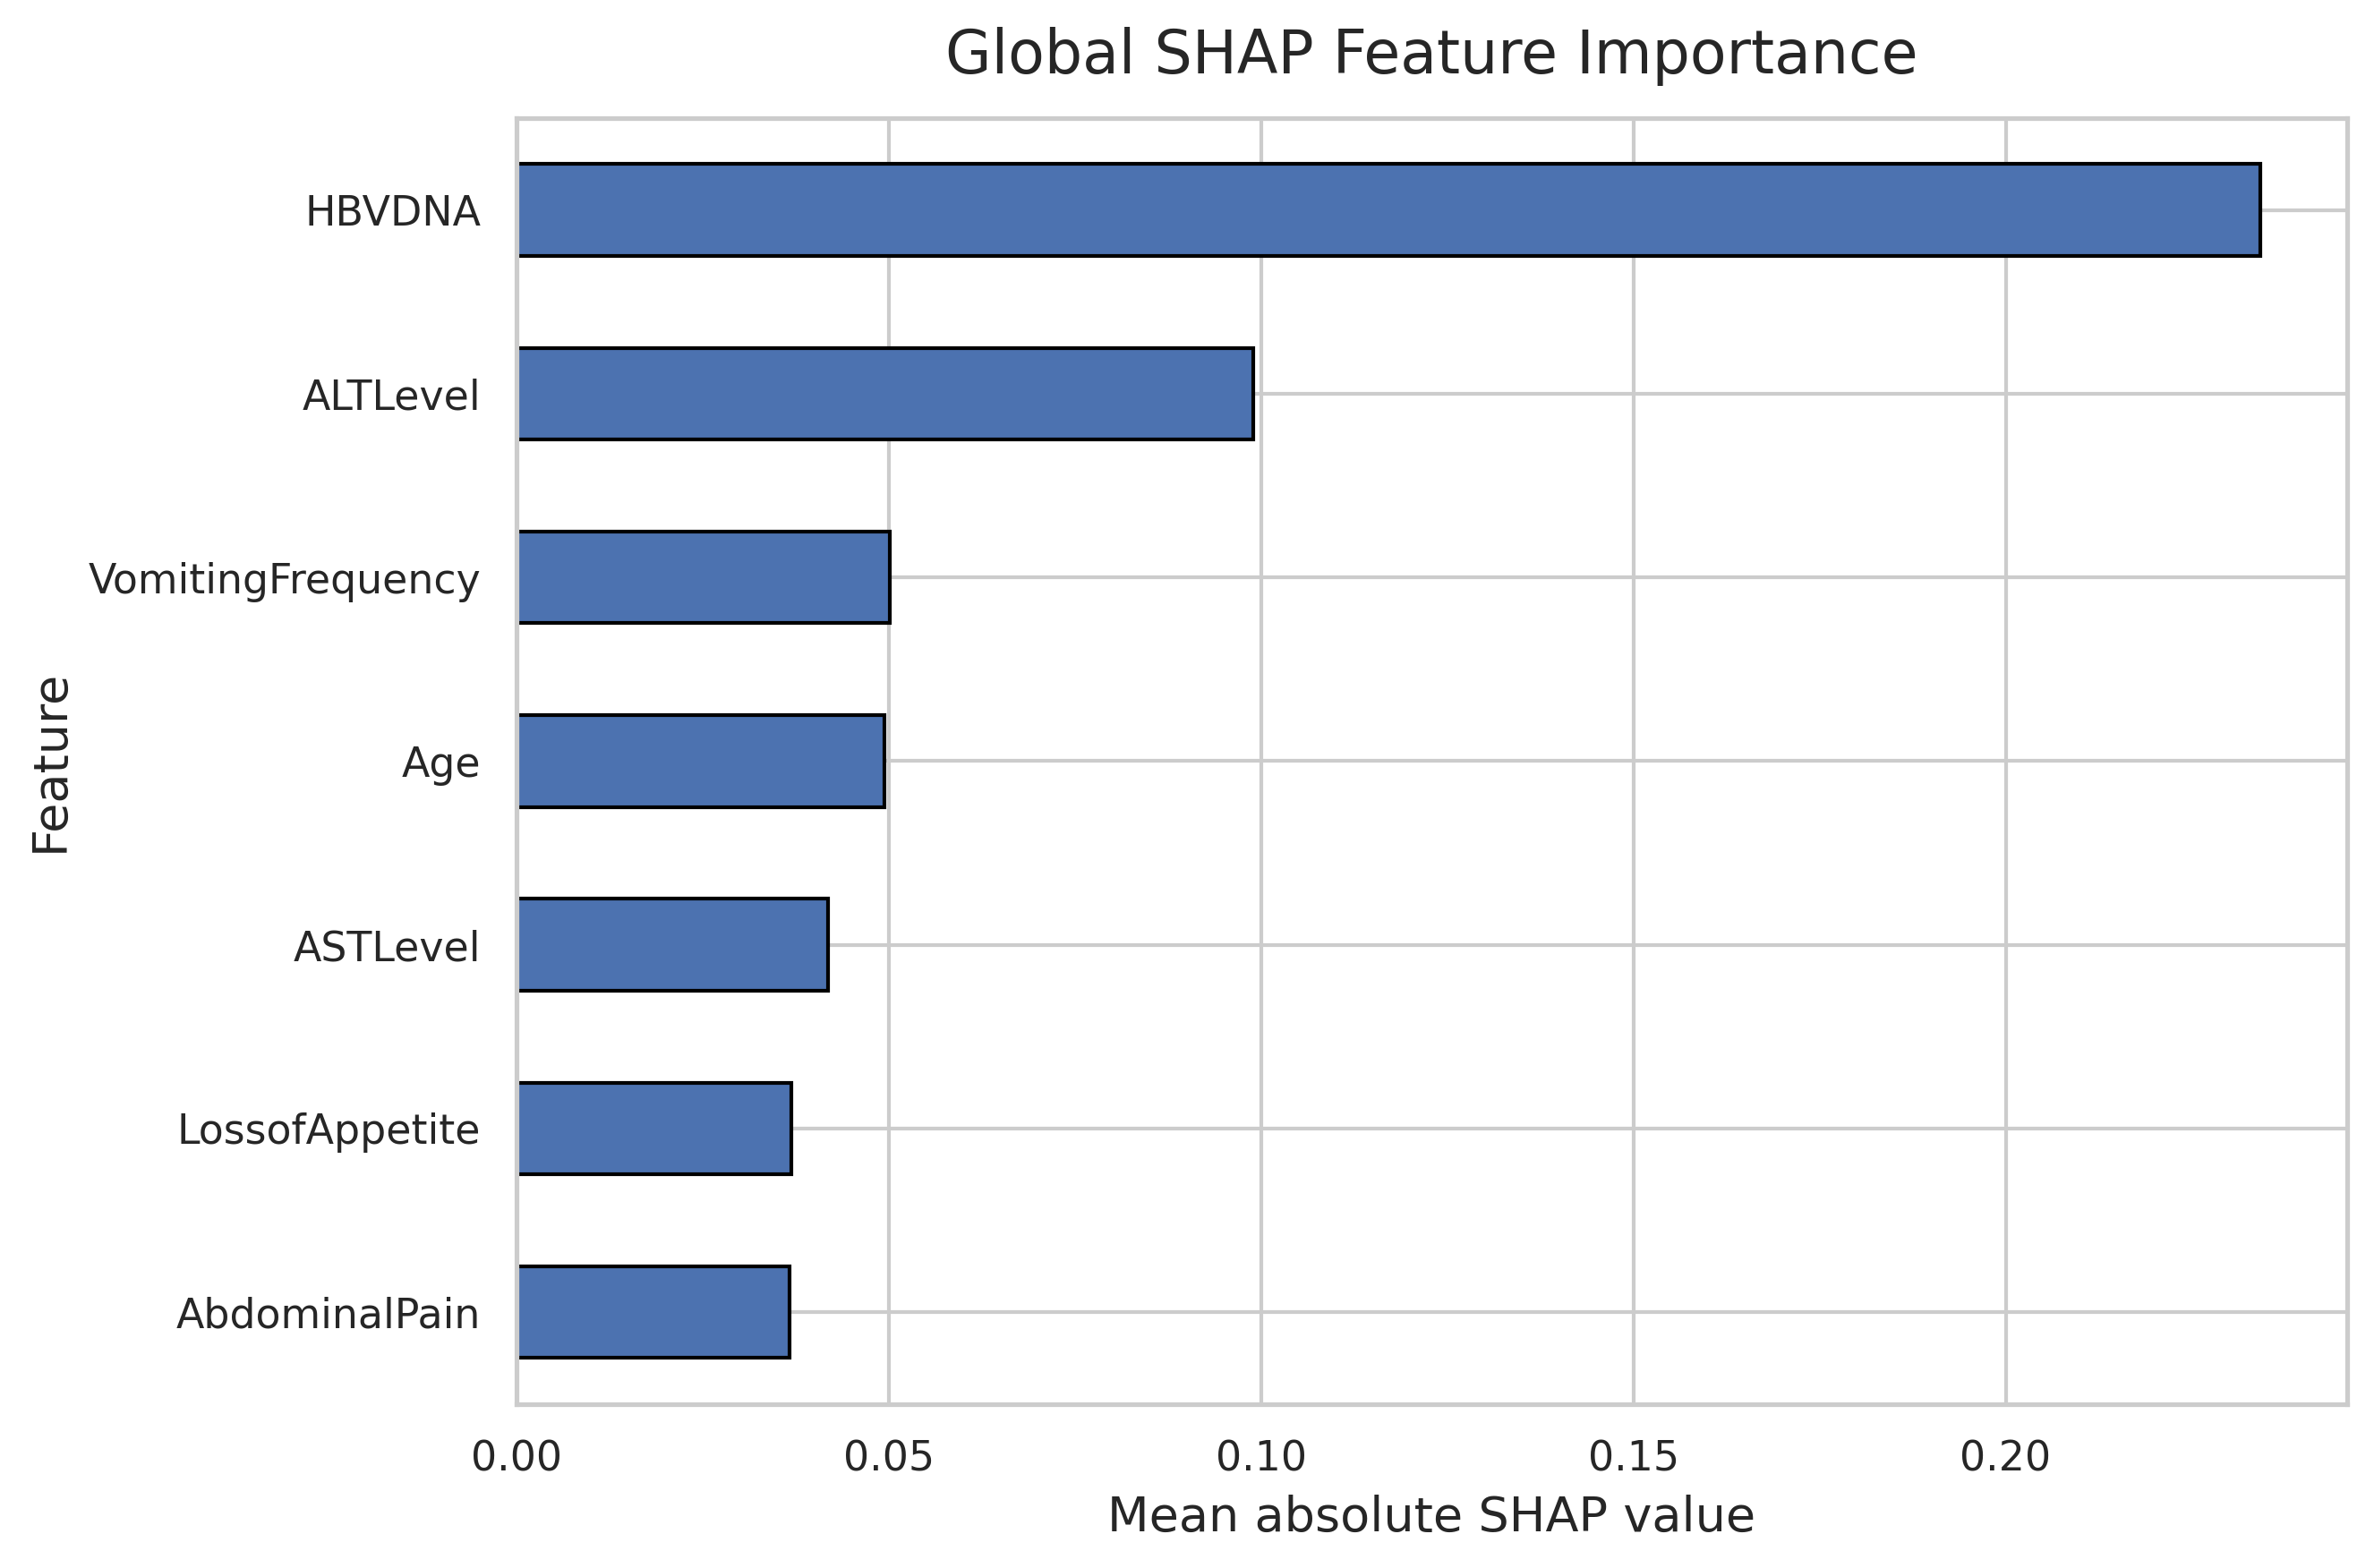

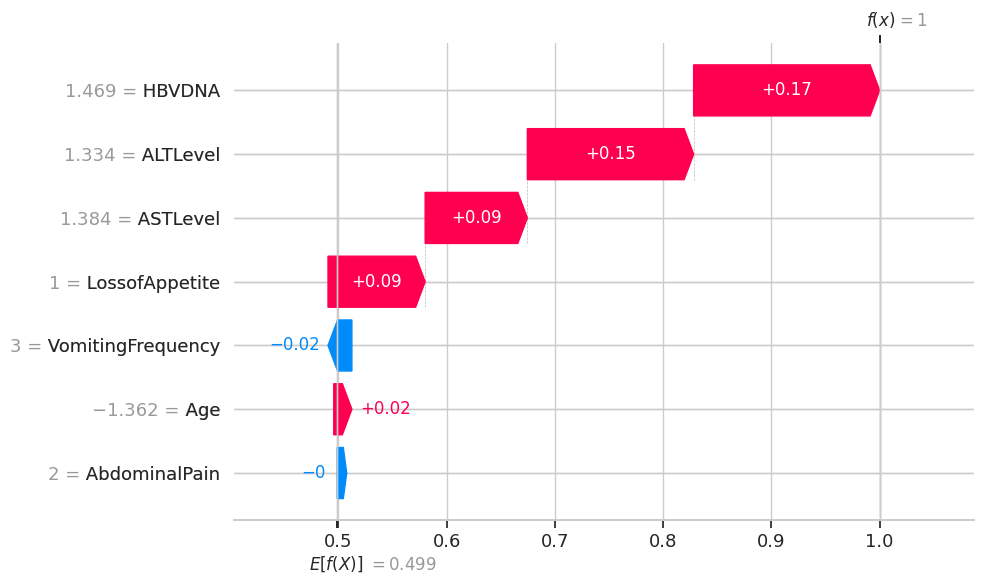

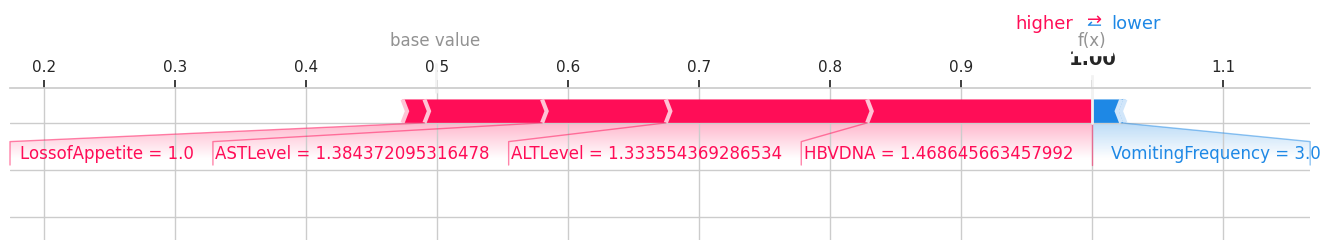

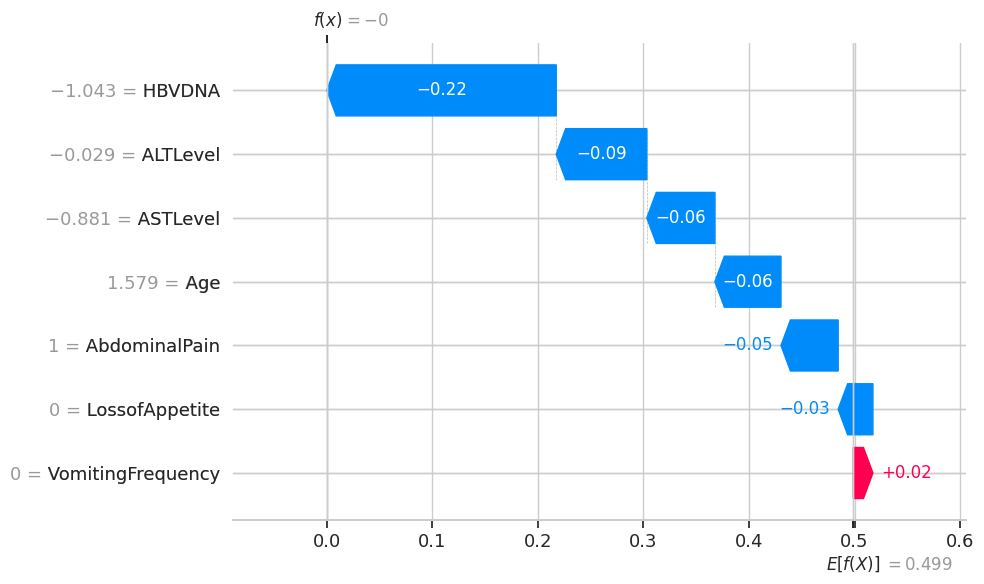

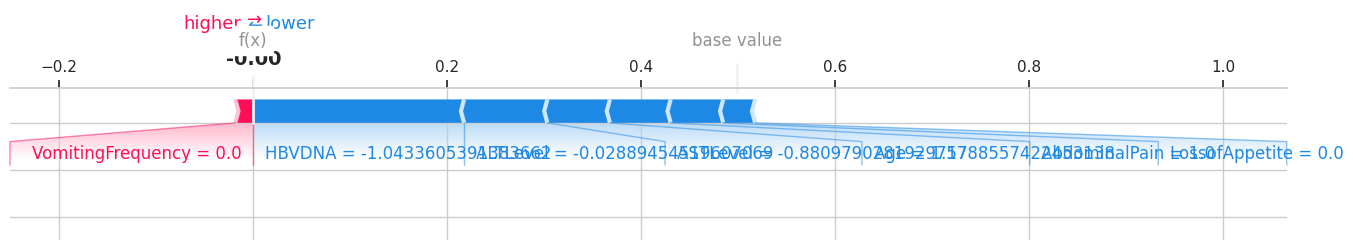

Positive-case probability: 1.0


,Feature,Transformed_value,SHAP_value
0,HBVDNA,1.468646,0.171859
1,ALTLevel,1.333554,0.153630
2,ASTLevel,1.384372,0.094417
3,LossofAppetite,1.000000,0.089739
5,Age,-1.361672,0.016769
4,AbdominalPain,2.000000,-0.003156
6,VomitingFrequency,3.000000,-0.022042


Negative-case probability: 0.0


,Feature,Transformed_value,SHAP_value
0,HBVDNA,-1.043361,-0.217321
1,ALTLevel,-0.028895,-0.085838
2,ASTLevel,-0.880979,-0.064506
5,Age,1.578856,-0.062580
4,AbdominalPain,1.000000,-0.054199
3,LossofAppetite,0.000000,-0.032903
6,VomitingFrequency,0.000000,0.018563


Saved: /content/drive/MyDrive/HBV_RF_Final_Outputs/FINAL_SHAP_FIGURES.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import zipfile
from pathlib import Path
from sklearn.base import clone
from google.colab import files

OUT_DIR = Path("/content/drive/MyDrive/HBV_RF_Final_Outputs")
SHAP_DIR = OUT_DIR / "FINAL_SHAP_FIGURES"
SHAP_DIR.mkdir(parents=True, exist_ok=True)

# Refit the corrected seed-42 pipeline using the selected RF configuration
final_seed42_pipeline = clone(tuned_pipelines["Random Forest"])
final_seed42_pipeline.set_params(
    smote__random_state=42,
    model__random_state=42
)
final_seed42_pipeline.fit(X_outer_train_42, y_outer_train_42)

preprocessor = final_seed42_pipeline.named_steps["preprocess"]
final_rf_model = final_seed42_pipeline.named_steps["model"]

X_train_transformed = preprocessor.transform(X_outer_train_42)
X_test_transformed = preprocessor.transform(X_outer_test_42)

feature_names = FINAL_FEATURES
test_probabilities = final_seed42_pipeline.predict_proba(
    X_outer_test_42
)[:, 1]
test_predictions = (test_probabilities >= 0.34).astype(int)
y_test_array = y_outer_test_42.to_numpy()

# SHAP values for the positive class
explainer = shap.TreeExplainer(final_rf_model)
raw_shap_values = explainer.shap_values(X_test_transformed)

if isinstance(raw_shap_values, list):
    positive_shap_values = raw_shap_values[1]
    base_value = explainer.expected_value[1]
elif np.asarray(raw_shap_values).ndim == 3:
    positive_shap_values = np.asarray(raw_shap_values)[:, :, 1]
    base_value = np.asarray(explainer.expected_value)[1]
else:
    positive_shap_values = np.asarray(raw_shap_values)
    expected = np.asarray(explainer.expected_value)
    base_value = expected.reshape(-1)[-1]

# Select one correctly classified positive and negative case
positive_candidates = np.where(
    (y_test_array == 1) & (test_predictions == 1)
)[0]
negative_candidates = np.where(
    (y_test_array == 0) & (test_predictions == 0)
)[0]

positive_index = positive_candidates[
    np.argmax(test_probabilities[positive_candidates])
]
negative_index = negative_candidates[
    np.argmin(test_probabilities[negative_candidates])
]

# Figure 9: Global SHAP importance
mean_abs_shap = np.abs(positive_shap_values).mean(axis=0)
importance = pd.Series(
    mean_abs_shap,
    index=feature_names
).sort_values()

fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
importance.plot(
    kind="barh",
    ax=ax,
    color="#4C72B0",
    edgecolor="black"
)
ax.set_xlabel("Mean absolute SHAP value", fontsize=13)
ax.set_ylabel("Feature", fontsize=13)
ax.set_title(
    "Global SHAP Feature Importance",
    fontsize=16,
    pad=12
)
ax.tick_params(labelsize=11)
plt.tight_layout()
figure9_path = SHAP_DIR / "Figure_9_revised.png"
plt.savefig(figure9_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

# Create SHAP explanation objects
positive_explanation = shap.Explanation(
    values=positive_shap_values[positive_index],
    base_values=base_value,
    data=X_test_transformed[positive_index],
    feature_names=feature_names
)

negative_explanation = shap.Explanation(
    values=positive_shap_values[negative_index],
    base_values=base_value,
    data=X_test_transformed[negative_index],
    feature_names=feature_names
)

# Figure 10: Positive waterfall
shap.plots.waterfall(
    positive_explanation,
    max_display=7,
    show=False
)
plt.gcf().set_size_inches(10, 6)
plt.tight_layout()
figure10_path = SHAP_DIR / "Figure_10_revised.png"
plt.savefig(figure10_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

# Figure 11: Positive force plot
shap.force_plot(
    base_value,
    positive_shap_values[positive_index],
    X_test_transformed[positive_index],
    feature_names=feature_names,
    matplotlib=True,
    show=False,
    figsize=(14, 3)
)
plt.tight_layout()
figure11_path = SHAP_DIR / "Figure_11_revised.png"
plt.savefig(figure11_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

# Figure 12: Negative waterfall
shap.plots.waterfall(
    negative_explanation,
    max_display=7,
    show=False
)
plt.gcf().set_size_inches(10, 6)
plt.tight_layout()
figure12_path = SHAP_DIR / "Figure_12_revised.png"
plt.savefig(figure12_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

# Figure 13: Negative force plot
shap.force_plot(
    base_value,
    positive_shap_values[negative_index],
    X_test_transformed[negative_index],
    feature_names=feature_names,
    matplotlib=True,
    show=False,
    figsize=(14, 3)
)
plt.tight_layout()
figure13_path = SHAP_DIR / "Figure_13_revised.png"
plt.savefig(figure13_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

# Print local contributions for manuscript verification
positive_contributions = pd.DataFrame({
    "Feature": feature_names,
    "Transformed_value": X_test_transformed[positive_index],
    "SHAP_value": positive_shap_values[positive_index]
}).sort_values("SHAP_value", ascending=False)

negative_contributions = pd.DataFrame({
    "Feature": feature_names,
    "Transformed_value": X_test_transformed[negative_index],
    "SHAP_value": positive_shap_values[negative_index]
}).sort_values("SHAP_value")

print("Positive-case probability:", test_probabilities[positive_index])
display(positive_contributions)

print("Negative-case probability:", test_probabilities[negative_index])
display(negative_contributions)

# Download all five figures as one ZIP file
zip_path = OUT_DIR / "FINAL_SHAP_FIGURES.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for image_path in [
        figure9_path,
        figure10_path,
        figure11_path,
        figure12_path,
        figure13_path
    ]:
        zip_file.write(image_path, arcname=image_path.name)

print("Saved:", zip_path)
files.download(str(zip_path))